# CSCI104 Option B – Exam Score Predictor (Model Training)

**Question:** Given a student's study habits and history, what exam score are they likely to get?

**Intended user:** a university student (or academic advisor) planning study time before an exam.

**Dataset:** *Student Performance Factors* – Kaggle
https://www.kaggle.com/datasets/lainguyn123/student-performance-factors

**Inputs (5, all known before the exam):** `Hours_Studied`, `Attendance`, `Previous_Scores`, `Tutoring_Sessions`, `Access_to_Resources`
**Target:** `Exam_Score` (a number → regression)

In Colab: open the **Files** panel and upload `StudentPerformanceFactors.csv` before running.

In [1]:
from pathlib import Path
from importlib.metadata import version
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder

## 1. Load and preview the data

In [2]:
df = pd.read_csv("StudentPerformanceFactors.csv")

numeric_features = ["Hours_Studied", "Attendance", "Previous_Scores", "Tutoring_Sessions"]
categorical_features = ["Access_to_Resources"]
features = numeric_features + categorical_features
target = "Exam_Score"

print("Shape:", df.shape)
df[features + [target]].head()

Shape: (6607, 20)


,Hours_Studied,Attendance,Previous_Scores,Tutoring_Sessions,Access_to_Resources,Exam_Score
0,23,84,73,0,High,67
1,19,64,59,2,Medium,61
2,24,98,91,2,Medium,74
3,29,89,98,1,Medium,71
4,19,92,65,3,Medium,70


In [3]:
df[features + [target]].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,NaN,NaN,NaN,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,NaN,NaN,NaN,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Previous_Scores,6607.0,NaN,NaN,NaN,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6607.0,NaN,NaN,NaN,1.493719,1.23057,0.0,1.0,1.0,2.0,8.0
Access_to_Resources,6607,3,Medium,3319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Exam_Score,6607.0,NaN,NaN,NaN,67.235659,3.890456,55.0,65.0,67.0,69.0,101.0


## 2. Check missing values and duplicates

In [4]:
print("Missing values in the columns we use:")
print(df[features + [target]].isna().sum())
print()
print("Missing values in the whole file (columns we do NOT use):")
print(df.isna().sum()[df.isna().sum() > 0])
print()
print("Duplicate rows:", df.duplicated().sum())
print("Exam scores above 100:", (df[target] > 100).sum())
print("Access_to_Resources categories:", sorted(df["Access_to_Resources"].unique()))

Missing values in the columns we use:
Hours_Studied          0
Attendance             0
Previous_Scores        0
Tutoring_Sessions      0
Access_to_Resources    0
Exam_Score             0
dtype: int64

Missing values in the whole file (columns we do NOT use):
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Duplicate rows: 0
Exam scores above 100: 1
Access_to_Resources categories: ['High', 'Low', 'Medium']


### Cleaning decisions
* **Duplicates:** none were found, but `drop_duplicates()` is kept so the notebook stays safe if the file changes.
* **Missing values:** our five inputs and the target have no gaps. The only gaps are in columns we don't use (`Teacher_Quality`, `Parental_Education_Level`, `Distance_from_Home`). We still put a **median imputer** (numbers) and **most-frequent imputer** (category) inside the pipeline so a blank value can never crash a prediction.
* **Impossible target:** one row has `Exam_Score = 101`, which is above the 100-point maximum, so it's removed as a data-entry error.
* **Leakage check:** every input is known *before* the exam. We don't use anything measured after it.

In [5]:
data = df.drop_duplicates().dropna(subset=[target])
data = data[data[target] <= 100]
print("Rows after cleaning:", len(data), "(removed", len(df) - len(data), ")")

Rows after cleaning: 6606 (removed 1 )


## 3. Quick look at the relationships

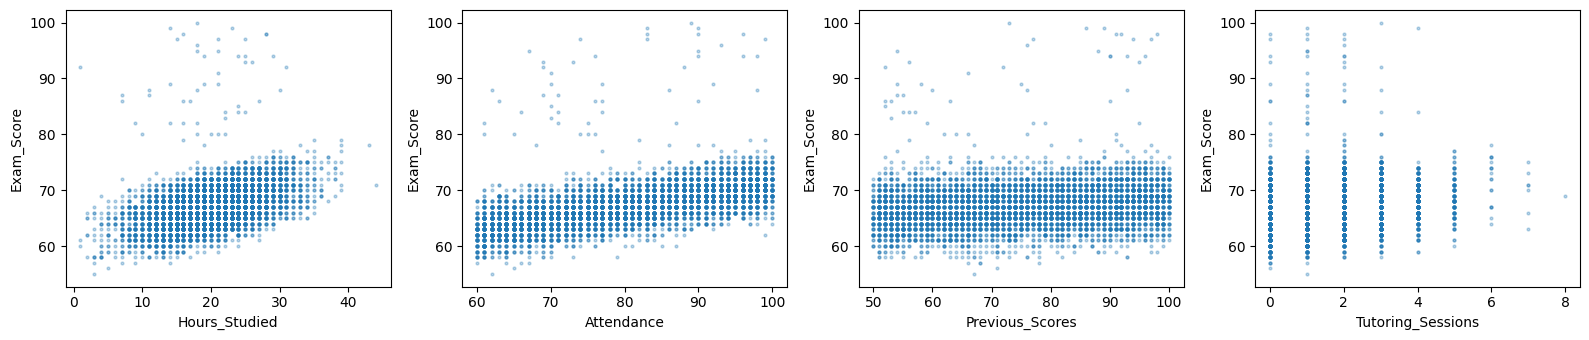

Hours_Studied        0.447
Attendance           0.582
Previous_Scores      0.174
Tutoring_Sessions    0.154
Exam_Score           1.000
Name: Exam_Score, dtype: float64
Access_to_Resources
High      68.09
Low       66.20
Medium    67.12
Name: Exam_Score, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, numeric_features):
    ax.scatter(data[col], data[target], s=4, alpha=0.3)
    ax.set_xlabel(col); ax.set_ylabel(target)
plt.tight_layout(); plt.show()
print(data[numeric_features + [target]].corr()[target].round(3))
print(data.groupby("Access_to_Resources")[target].mean().round(2))

## 4. Split into train and test (80 / 20, `random_state=42`)
Preprocessing is inside the pipeline, so imputers and the one-hot encoder learn **only from the training rows**.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    data[features], data[target], test_size=0.2, random_state=42)
print("Train rows:", len(X_train), " Test rows:", len(X_test))

Train rows: 5284  Test rows: 1322


## 5. Build and train the model
**Why linear regression?** The target is a number, the scatter plots show roughly straight-line trends, and a linear model is easy to explain: each coefficient says how many points one extra unit of an input adds.

In [8]:
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore")), categorical_features),
])
model = Pipeline([("preprocess", preprocess), ("regressor", LinearRegression())])
model.fit(X_train, y_train)

names = model.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(model.named_steps["regressor"].coef_, index=names).round(3)
print("Intercept:", round(model.named_steps["regressor"].intercept_, 2))
coefs

Intercept: 41.25


num__Hours_Studied                 0.290
num__Attendance                    0.198
num__Previous_Scores               0.047
num__Tutoring_Sessions             0.490
cat__Access_to_Resources_High      1.002
cat__Access_to_Resources_Low      -1.027
cat__Access_to_Resources_Medium    0.024
dtype: float64

## 6. Evaluate on the held-out test set

In [9]:
pred = model.predict(X_test)
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)
baseline_mae = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
within_2 = (np.abs(y_test - pred) <= 2).mean()

print(f"Test MAE:            {mae:.2f} points")
print(f"Baseline MAE (guess the average): {baseline_mae:.2f} points")
print(f"R²:                  {r2:.3f}")
print(f"Predictions within ±2 points: {within_2:.0%}")

Test MAE:            1.11 points
Baseline MAE (guess the average): 2.76 points
R²:                  0.711
Predictions within ±2 points: 87%


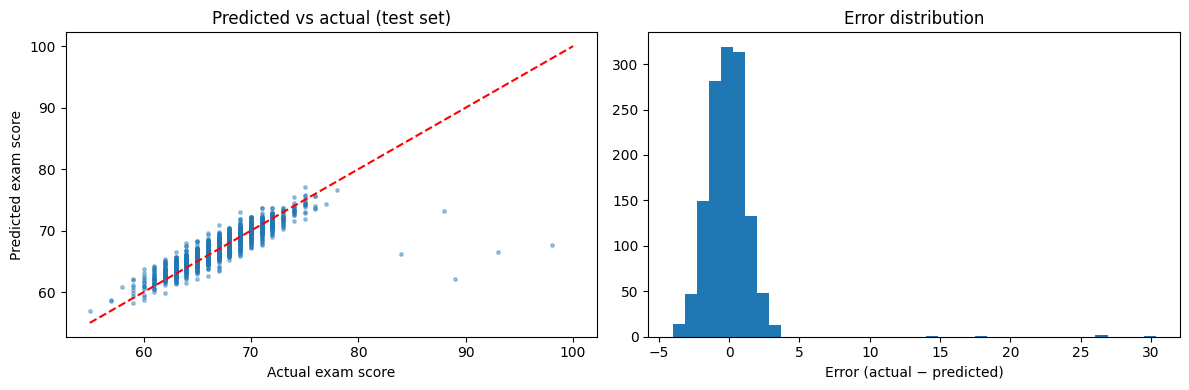

Largest under-predictions (actual much higher than predicted):
6393    30.3
217     26.9
4583    26.4
3932    17.9
1607    14.8
Name: Exam_Score, dtype: float64


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test, pred, s=6, alpha=0.4)
axes[0].plot([55, 100], [55, 100], "r--")
axes[0].set_xlabel("Actual exam score"); axes[0].set_ylabel("Predicted exam score")
axes[0].set_title("Predicted vs actual (test set)")
axes[1].hist(y_test - pred, bins=40)
axes[1].set_xlabel("Error (actual − predicted)"); axes[1].set_title("Error distribution")
plt.tight_layout(); plt.show()

errors = y_test - pred
print("Largest under-predictions (actual much higher than predicted):")
print(errors.sort_values(ascending=False).head(5).round(1))

### What the result means
The **MAE is about 1.1 points**: on students the model never saw, its estimate is typically about 1 point away from the real exam score. That's well below the ~2.8-point error of always guessing the average, so the inputs carry real information. Attendance and hours studied have the biggest effect.

**Limitation:** the errors aren't symmetric. A small group of students scored far *higher* than predicted (the long right tail in the histogram), and the model can't explain them with these five inputs. The data also only covers 60–100% attendance and 1–44 study hours per week, so estimates outside those ranges are extrapolation. Finally, this is a public dataset of (likely synthetic) school records, not University of Khorfakkan students, so it's a study-planning aid, not an official grade forecast.

## 7. Try one new student (sanity check)

In [11]:
example = pd.DataFrame([{
    "Hours_Studied": 20, "Attendance": 85, "Previous_Scores": 75,
    "Tutoring_Sessions": 2, "Access_to_Resources": "Medium"}])
print("Estimated exam score:", round(model.predict(example)[0], 1))

Estimated exam score: 68.4


## 8. Export the model and requirements.txt
Download both files from the Files panel and put them next to `streamlit_app.py`.

In [12]:
joblib.dump(model, "model.joblib")
packages = ["pandas", "numpy", "scipy", "scikit-learn", "joblib"]
lines = ["streamlit"] + [f"{p}=={version(p)}" for p in packages]
Path("requirements.txt").write_text("\n".join(lines) + "\n")
print(Path("requirements.txt").read_text())
print("Training Python version:", sys.version.split()[0])

streamlit
pandas==2.3.3
numpy==2.2.6
scipy==1.15.3
scikit-learn==1.7.2
joblib==1.5.3

Training Python version: 3.10.4
